# **TP N°4 : Les Réseaux de Neurones Récurrents**

**Elaboré par:** Ayeb Farah


**Objectif:** Comparer trois architectures de réseaux de neurones profonds pour la classification de sentiments :

* Réseau Dense (Fully Connected)
* Réseau Convolutionnel (CNN)
* LSTM (Long Short-Term Memory)

Le dataset utilisé est IMDB (50 000 critiques de films, positif/négatif).


## **Importation des bibliothèques :**

In [1]:
import pandas as pd
import numpy as np
import re
import nltk
from nltk.corpus import stopwords
from numpy import array
from tensorflow.keras.preprocessing.text import one_hot
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Activation, Dropout, Dense
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Conv1D
from tensorflow.keras.layers import GlobalMaxPooling1D
from tensorflow.keras.layers import LSTM
from tensorflow.keras.layers import Embedding
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
import matplotlib.pyplot as plt
import seaborn as sns
from numpy import asarray
from numpy import zeros
nltk.download('stopwords')


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [2]:
# Charger le dataset (adapter le chemin si nécessaire)
movie_reviews = pd.read_csv('/content/drive/MyDrive/TP4_DL/IMDB Dataset.csv')

print('Dimension du dataset :', movie_reviews.shape)
print('\nValeurs nulles par colonne :')
print(movie_reviews.isnull().sum())
print('\n5 premières lignes :')
movie_reviews.head()

Dimension du dataset : (50000, 2)

Valeurs nulles par colonne :
review       0
sentiment    0
dtype: int64

5 premières lignes :


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


**Visualisation de l'équilibre du dataset**

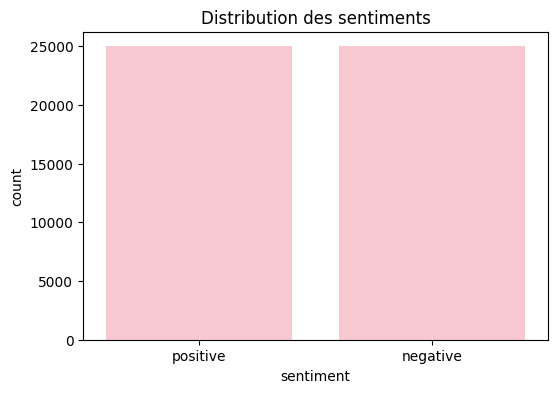

In [3]:
plt.figure(figsize=(6,4))
sns.countplot(x='sentiment', color='pink', data=movie_reviews)
plt.title('Distribution des sentiments')
plt.show()

--> Dataset parfaitement équilibré

In [4]:
print("\n4ème review (avant prétraitement):\n", movie_reviews['review'][3])


4ème review (avant prétraitement):
 Basically there's a family where a little boy (Jake) thinks there's a zombie in his closet & his parents are fighting all the time.<br /><br />This movie is slower than a soap opera... and suddenly, Jake decides to become Rambo and kill the zombie.<br /><br />OK, first of all when you're going to make a film you must Decide if its a thriller or a drama! As a drama the movie is watchable. Parents are divorcing & arguing like in real life. And then we have Jake with his closet which totally ruins all the film! I expected to see a BOOGEYMAN similar movie, and instead i watched a drama with some meaningless thriller spots.<br /><br />3 out of 10 just for the well playing parents & descent dialogs. As for the shots with Jake: just ignore them.


--> On remarque que les reviews sont des ont des balises HTML (<br />), ponctuation, chiffres, caractères spéciaux. Le texte brut est "sale" et doit être nettoyé avant d'être utilisé.

## **Prétraitement de données**



| Étape | Action | Exemple |
|---|---|---|
| `remove_tags` | Supprime les balises HTML comme `<br />`, `<b>`, etc. | `<br />` → `` |
| `re.sub('[^a-zA-Z]', ' ', ...)` | Garde uniquement les lettres (supprime chiffres & ponctuation) | `good!` → `good ` |
| `re.sub(r"\s+[a-zA-Z]\s+", ' ', ...)` | Supprime les mots d'une seule lettre | ` a ` → ` ` |
| `re.sub(r'\s+', ' ', ...)` | Réduit les espaces multiples en un seul espace | `  ` → ` ` |

In [5]:
# Regex pour détecter les balises HTML
TAG_RE = re.compile(r'<[^>]+>')

def remove_tags(text):
    """Supprime toutes les balises HTML du texte."""
    return TAG_RE.sub('', text)

def preprocess_text(sen):
    """Nettoie un texte brut pour le rendre utilisable par un modèle NLP."""

    # Étape 1 : Supprimer les balises HTML
    sentence = remove_tags(sen)

    # Étape 2 : Supprimer la ponctuation et les chiffres (garder uniquement a-z, A-Z)
    sentence = re.sub('[^a-zA-Z]', ' ', sentence)

    # Étape 3 : Supprimer les caractères isolés (ex: 's', 'a')
    sentence = re.sub(r"\s+[a-zA-Z]\s+", ' ', sentence)

    # Étape 4 : Supprimer les espaces multiples
    sentence = re.sub(r'\s+', ' ', sentence)

    return sentence

In [6]:
# Appliquer le prétraitement sur tous les reviews
X = []
sentences = list(movie_reviews['review'])
for sen in sentences:
    X.append(preprocess_text(sen))

# Afficher le 4ème review APRÈS prétraitement
print('4ème review après prétraitement :')
print(X[3])

4ème review après prétraitement :
Basically there a family where little boy Jake thinks there a zombie in his closet his parents are fighting all the time This movie is slower than soap opera and suddenly Jake decides to become Rambo and kill the zombie OK first of all when you re going to make film you must Decide if its thriller or drama As drama the movie is watchable Parents are divorcing arguing like in real life And then we have Jake with his closet which totally ruins all the film expected to see BOOGEYMAN similar movie and instead watched drama with some meaningless thriller spots out of just for the well playing parents descent dialogs As for the shots with Jake just ignore them 


--> Plus de balises HTML, plus de chiffres, texte plus propre et uniforme

In [7]:
# Convertir les étiquettes textuelles en valeurs numériques
# 'positive' → 1  |  'negative' → 0
y = movie_reviews['sentiment']
y = np.array(list(map(lambda x: 1 if x == 'positive' else 0, y)))

print('Distribution des étiquettes numériques :')
print('Positif (1) :', np.sum(y == 1))
print('Négatif (0) :', np.sum(y == 0))

Distribution des étiquettes numériques :
Positif (1) : 25000
Négatif (0) : 25000


In [8]:
# Division en training set (80%) et test set (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print('Taille du training set :', len(X_train))
print('Taille du test set     :', len(X_test))

Taille du training set : 40000
Taille du test set     : 10000


## **La couche d'Embedding**

Les réseaux de neurones ne comprennent pas les mots directement. On doit les convertir en vecteurs numériques. Il existe deux approches :

* Keras Tokenizer : crée un index vocabulaire → chaque mot = un entier
* GloVe : vecteurs pré-entraînés sur des milliards de mots (sémantique capturée)

**Processus :**
Texte → Séquence d'entiers → Padding (longueur fixe) → Matrice d'embeddings GloVe

Nous allons créer un dictionnaire word-to-index. Dans le dictionnaire word-to-index

In [9]:
# --- Tokenisation ---
# num_words=5000 : on ne garde que les 5000 mots les plus fréquents
tokenizer = Tokenizer(num_words=5000)
tokenizer.fit_on_texts(X_train)  # apprend le vocabulaire sur le train uniquement

# Convertir chaque phrase en séquence d'entiers
X_train = tokenizer.texts_to_sequences(X_train)
X_test  = tokenizer.texts_to_sequences(X_test)

print('Exemple — 1ère phrase tokenisée :', X_train[0][:10], '...')

Exemple — 1ère phrase tokenisée : [9, 43, 786, 2121, 524, 299, 1, 104, 1860, 1989] ...


Ce code effectue la tokenisation et la conversion des textes en séquences d'entiers.

**Objectif :** Créer un objet Tokenizer qui ne gardera que les 5000 mots les plus fréquents du corpus.

num_words=5000 : limite le vocabulaire aux 5000 mots les plus courants

Les mots rares (au-delà de 5000) sont ignorés (remplacés par OOV - Out Of Vocabulary)

Cela permet de réduire la dimensionnalité et le bruit

Le Tokenizer va :

Parcourir tous les textes de X_train

Compter la fréquence de chaque mot

Assigner un index unique à chaque mot (de 1 à N)

Créer un dictionnaire word_index : {'the': 1, 'and': 2, 'a': 3, ...}



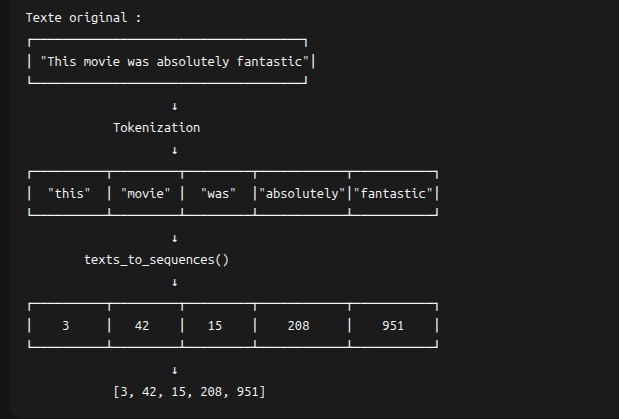

### **Taille de Vocabulaire + remplissage:**

In [10]:
# Taille du vocabulaire +1 car l'index 0 est réservé (padding)
vocab_size = len(tokenizer.word_index) + 1
print(f"Taille du vocabulaire: {vocab_size}")

Taille du vocabulaire: 92547


In [11]:
# --- Padding ---
# Toutes les séquences doivent avoir la même longueur pour être traitées en batch, Le réseau de neurones a besoin d'entrées de taille identique pour fonctionner.
# padding='post' : ajoute les 0 à la FIN de la séquence
# maxlen=100 : on tronque/complète à 100 tokens
maxlen = 100
X_train = pad_sequences(X_train, padding='post', maxlen=maxlen)
X_test  = pad_sequences(X_test,  padding='post', maxlen=maxlen)

print('Shape X_train après padding :', X_train.shape)
print('Shape X_test après padding  :', X_test.shape)

Shape X_train après padding : (40000, 100)
Shape X_test après padding  : (10000, 100)


### **Chargement des embeddings GloVe**

GloVe (Global Vectors for Word Representation) est une méthode d'apprentissage de word embeddings (représentations vectorielles de mots)

In [12]:
embeddings_dictionary = dict()
glove_file = open('/content/drive/MyDrive/TP4_DL/glove.6B.100d.txt', encoding='utf8')

for line in glove_file:
    records = line.split()
    word = records[0]
    vector_dimensions = asarray(records[1:], dtype='float32')
    embeddings_dictionary[word] = vector_dimensions

glove_file.close()
print('GloVe chargé — nombre de mots :', len(embeddings_dictionary))

GloVe chargé — nombre de mots : 400000


**Afficher les 5 premiers mots et leurs vecteurs**

In [13]:
print("Les 5 premières entrées du dictionnaire GloVe :")
print("-" * 60)

for i, (word, vector) in enumerate(list(embeddings_dictionary.items())[:5]):
    print(f"\n{i+1}. Mot : '{word}'")
    print(f"   Vecteur : {vector[:5]}...")
    print(f"   Dimension du vecteur : {len(vector)}")
    print(f"   Type : {type(vector)}")

Les 5 premières entrées du dictionnaire GloVe :
------------------------------------------------------------

1. Mot : 'the'
   Vecteur : [-0.038194 -0.24487   0.72812  -0.39961   0.083172]...
   Dimension du vecteur : 100
   Type : <class 'numpy.ndarray'>

2. Mot : ','
   Vecteur : [-0.10767  0.11053  0.59812 -0.54361  0.67396]...
   Dimension du vecteur : 100
   Type : <class 'numpy.ndarray'>

3. Mot : '.'
   Vecteur : [-0.33979  0.20941  0.46348 -0.64792 -0.38377]...
   Dimension du vecteur : 100
   Type : <class 'numpy.ndarray'>

4. Mot : 'of'
   Vecteur : [-0.1529  -0.24279  0.89837  0.16996  0.53516]...
   Dimension du vecteur : 100
   Type : <class 'numpy.ndarray'>

5. Mot : 'to'
   Vecteur : [-0.1897    0.050024  0.19084  -0.049184 -0.089737]...
   Dimension du vecteur : 100
   Type : <class 'numpy.ndarray'>


**Construction de la matrice d'embeddings**

On crée une matrice qui fait le lien entre l'index d'un mot (dans notre tokenizer) et son vecteur GloVe.

Le but est d'associer chaque mot de notre corpus IMDB à son vecteur GloVe (qui contient déjà une connaissance riche du langage).

In [14]:
# Forme : (vocab_size, 100)
# Chaque ligne i contient le vecteur GloVe du mot ayant l'index i dans le tokenizer
# Si un mot du corpus n'est pas dans GloVe → sa ligne reste à zéro

embedding_matrix = zeros((vocab_size, 100))

for word, index in tokenizer.word_index.items():
    embedding_vector = embeddings_dictionary.get(word)
    if embedding_vector is not None:
        embedding_matrix[index] = embedding_vector

print('Matrice d\'embeddings construite :', embedding_matrix.shape)

Matrice d'embeddings construite : (92547, 100)


## **A. Classification avec un simple réseau de neurones**

**Architecture :**

Input (100 tokens) → Embedding(GloVe) → Flatten → Dense(1, sigmoid)


* Embedding : convertit chaque token en vecteur GloVe de dim 100 → sortie (100 × 100)
* Flatten : aplati le tensor 2D en vecteur 1D (100 × 100 = 10 000 valeurs)
* Dense(1, sigmoid) : classification binaire → sortie entre 0 et 1



In [15]:
# --- Construction du modèle Dense ---
model_dense = Sequential(name='Dense_Model')

# Couche Embedding avec les poids GloVe pré-entraînés (trainable=False → on ne réentraîne pas)
model_dense.add(Embedding(
    input_dim=vocab_size,
    output_dim=100,
    weights=[embedding_matrix],
    input_length=maxlen,
    trainable=False
))

# Flatten : transforme la sortie 2D (100, 100) en vecteur 1D (10000,)
model_dense.add(Flatten())

# Couche de sortie : 1 neurone avec sigmoïde → classification binaire
# sigmoid(x) : sortie ∈ [0,1] → interprétée comme probabilité d'être positif
model_dense.add(Dense(1, activation='sigmoid'))

# Compilation
model_dense.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['acc']
)

model_dense.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "Dense_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │     9,254,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,254,700 (35.30 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 9,254,700 (35.30 MB)

In [16]:
# --- Entraînement ---
# validation_split=0.2 : 20% du training set est utilisé pour valider à chaque époque
# Cela permet de détecter l'overfitting sans toucher au test set
history_dense = model_dense.fit(
    X_train, y_train,
    epochs=6,
    batch_size=128,
    verbose=1,
    validation_split=0.2
)

Epoch 1/6
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - acc: 0.6701 - loss: 0.6077 - val_acc: 0.7309 - val_loss: 0.5402
Epoch 2/6
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - acc: 0.7592 - loss: 0.4996 - val_acc: 0.7439 - val_loss: 0.5230
Epoch 3/6
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - acc: 0.7878 - loss: 0.4580 - val_acc: 0.7421 - val_loss: 0.5261
Epoch 4/6
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - acc: 0.7994 - loss: 0.4372 - val_acc: 0.7427 - val_loss: 0.5258
Epoch 5/6
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - acc: 0.8110 - loss: 0.4193 - val_acc: 0.7420 - val_loss: 0.5292
Epoch 6/6
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - acc: 0.8148 - loss: 0.4067 - val_acc: 0.7414 - val_loss: 0.5371


In [17]:
# --- Évaluation sur le test set ---
score_dense = model_dense.evaluate(X_test, y_test, verbose=1)
print('\n=== Réseau Dense ===')
print('Test Loss     :', round(score_dense[0], 4))
print('Test Accuracy :', round(score_dense[1], 4))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - acc: 0.7430 - loss: 0.5391

=== Réseau Dense ===
Test Loss     : 0.5391
Test Accuracy : 0.743


--> Performance satisfaisante (74.5% sur validation) mais perfectible. Le modèle aurait probablement été meilleur en s'arrêtant à l'époque 3 (val_acc=74.8%) plutôt qu'à l'époque 6 car le modèle commence à mémoriser plutôt qu'à généraliser (validation loss augmente)

**Tracer les fonctions de loss et de l'accuracy pour les training et test sets**

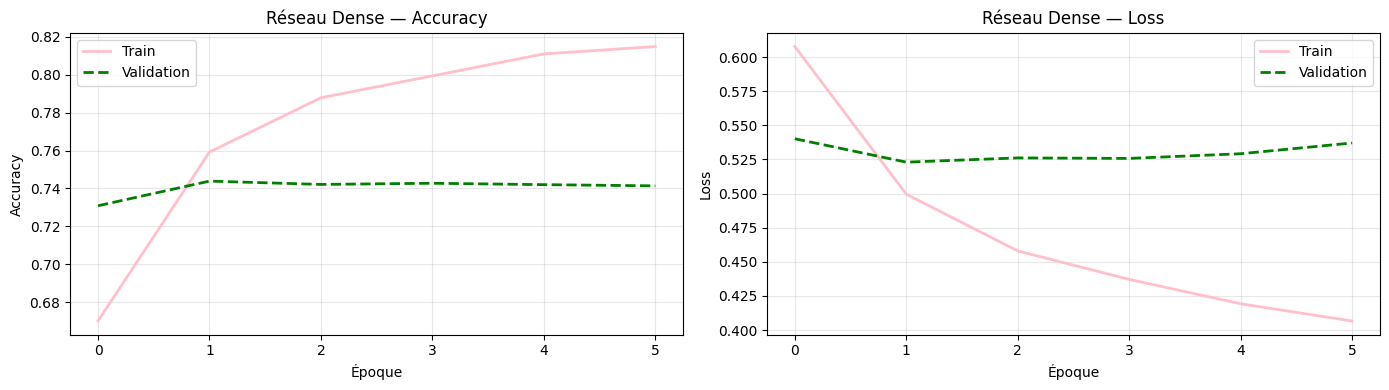

In [18]:
def plot_history(history, model_name):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    # Accuracy
    axes[0].plot(history.history['acc'],     label='Train', color='pink', linewidth=2)
    axes[0].plot(history.history['val_acc'], label='Validation', color='green', linestyle='--', linewidth=2)
    axes[0].set_title(f'{model_name} — Accuracy')
    axes[0].set_xlabel('Époque')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Loss
    axes[1].plot(history.history['loss'],     label='Train', color='pink', linewidth=2)
    axes[1].plot(history.history['val_loss'], label='Validation', color='green', linestyle='--', linewidth=2)
    axes[1].set_title(f'{model_name} — Loss')
    axes[1].set_xlabel('Époque')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_history(history_dense, 'Réseau Dense')

--> la perte d'entraînement continue de baisser alors que la perte de validation set stagne ou remonte → signe d'OVERFITTING léger. Le modèle Dense a peu de capacité à capturer des relations séquentielles dans le texte.

Le modèle apprend correctement au début, améliorant sa performance sur les données d'entraînement à chaque époque. Cependant, après quelques passages, on observe que la performance sur les données de validation cesse de progresser et reste stable, tandis que le modèle continue de s'améliorer sur les données d'entraînement. Cela indique un début de surapprentissage : le modèle commence à mémoriser les exemples d'entraînement plutôt qu'à apprendre des règles généralisables. Idéalement, il aurait fallu arrêter l'entraînement plus tôt, lorsque la performance sur la validation était à son maximum, pour obtenir un modèle qui généralise mieux sur de nouvelles données.

## **PARTIE B — Réseau Convolutionnel (CNN)**


**Architecture :**
```
Input → Embedding(GloVe) → Conv1D(128, kernel=5, relu) → GlobalMaxPooling1D → Dense(1, sigmoid)
```
- **Conv1D** : détecte des motifs locaux dans la séquence (ex: "not good", "very bad")
- **kernel_size=5** : chaque filtre observe 5 tokens à la fois (fenêtre glissante)
- **GlobalMaxPooling1D** : retient uniquement la valeur max de chaque filtre (feature la plus saillante)
- **Avantage vs Dense** : capture les n-grams locaux, moins de paramètres

In [19]:
# --- Construction du modèle CNN ---
model_cnn = Sequential(name='CNN_Model')

model_cnn.add(Embedding(
    input_dim=vocab_size,
    output_dim=100,
    weights=[embedding_matrix],
    input_length=maxlen,
    trainable=False
))

# Conv1D : 128 filtres, fenêtre de 5 tokens, activation ReLU
# ReLU : f(x) = max(0, x) — élimine les valeurs négatives, introduit la non-linéarité
model_cnn.add(Conv1D(128, 5, activation='relu'))

# GlobalMaxPooling : réduit chaque carte de features à sa valeur maximale
# → passe de (batch, longueur, 128) à (batch, 128)
model_cnn.add(GlobalMaxPooling1D())

# Couche de sortie
model_cnn.add(Dense(1, activation='sigmoid'))
model_cnn.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['acc']
)

model_cnn.summary()

Model: "CNN_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │     9,254,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,254,700 (35.30 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 9,254,700 (35.30 MB)

In [20]:
history_cnn = model_cnn.fit(
    X_train, y_train,
    epochs=6,
    batch_size=128,
    verbose=1,
    validation_split=0.2
)

Epoch 1/6
250/250 ━━━━━━━━━━━━━━━━━━━━ 37s 138ms/step - acc: 0.7562 - loss: 0.4946 - val_acc: 0.8244 - val_loss: 0.3911
Epoch 2/6
250/250 ━━━━━━━━━━━━━━━━━━━━ 33s 108ms/step - acc: 0.8378 - loss: 0.3677 - val_acc: 0.8367 - val_loss: 0.3618
Epoch 3/6
250/250 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - acc: 0.8667 - loss: 0.3153 - val_acc: 0.8481 - val_loss: 0.3474
Epoch 4/6
250/250 ━━━━━━━━━━━━━━━━━━━━ 40s 105ms/step - acc: 0.8884 - loss: 0.2760 - val_acc: 0.8503 - val_loss: 0.3417
Epoch 5/6
250/250 ━━━━━━━━━━━━━━━━━━━━ 40s 102ms/step - acc: 0.9009 - loss: 0.2488 - val_acc: 0.8480 - val_loss: 0.3427
Epoch 6/6
250/250 ━━━━━━━━━━━━━━━━━━━━ 49s 135ms/step - acc: 0.9199 - loss: 0.2171 - val_acc: 0.8484 - val_loss: 0.3399


313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - acc: 0.8490 - loss: 0.3354

=== CNN ===
Test Loss     : 0.3354
Test Accuracy : 0.849


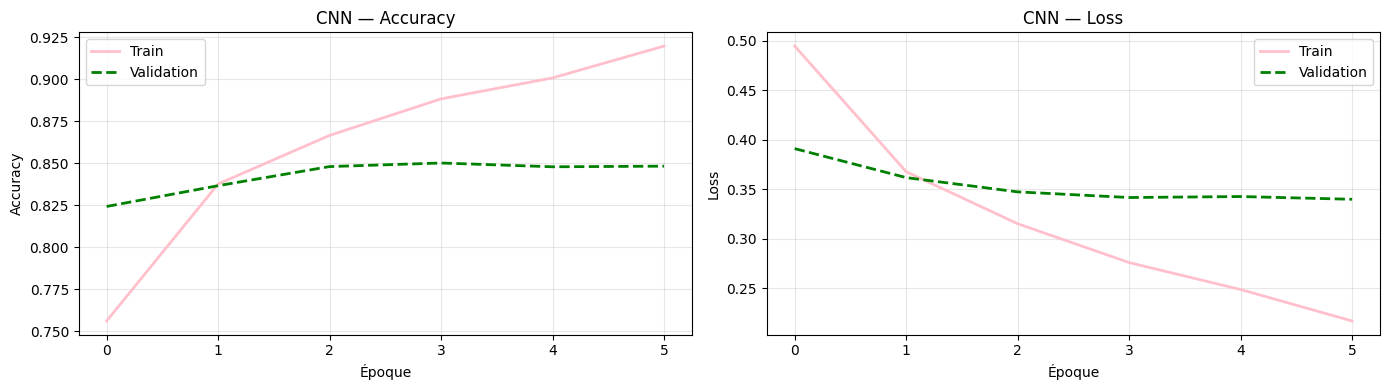

In [21]:
score_cnn = model_cnn.evaluate(X_test, y_test, verbose=1)
print('\n=== CNN ===')
print('Test Loss     :', round(score_cnn[0], 4))
print('Test Accuracy :', round(score_cnn[1], 4))

plot_history(history_cnn, 'CNN')

--> Le modèle CNN apprend très efficacement, atteignant 85.3% de précision sur la validation dès l'époque 5, avec une excellente généralisation et sans signe majeur de surapprentissage, ce qui est une nette amélioration par rapport au modèle dense.

--> Le CNN dépasse généralement le Dense car il capte les motifs locaux du texte

## **PARTIE C : LSTM (Long Short-Term Memory)**

### Pourquoi le LSTM ?
Un RNN simple souffre du **vanishing gradient** : il oublie les informations distantes.

Le **LSTM** résout ce problème grâce à 3 portes (gates) :
| Porte | Rôle |
|---|---|
| **Forget gate** | Décide quoi oublier de la mémoire |
| **Input gate** | Décide quelles nouvelles infos stocker |
| **Output gate** | Décide quoi retourner comme état caché |

### Architecture :
```
Input → Embedding(GloVe) → LSTM(128) → Dense(1, sigmoid)
```

In [22]:
# --- Construction du modèle LSTM ---
model_lstm = Sequential(name='LSTM_Model')

model_lstm.add(Embedding(
    input_dim=vocab_size,
    output_dim=100,
    weights=[embedding_matrix],
    input_length=maxlen,
    trainable=False
))

# LSTM avec 128 unités mémoire
# Par défaut : return_sequences=False → retourne seulement l'état final
# C'est ce qu'on veut pour la classification (un seul vecteur par phrase)
model_lstm.add(LSTM(128))

# Couche de sortie
model_lstm.add(Dense(1, activation='sigmoid'))

model_lstm.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['acc']
)

model_lstm.summary()

Model: "LSTM_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │     9,254,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,254,700 (35.30 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 9,254,700 (35.30 MB)

128 cellules mémoire --> je donne 128 mémoires au modèle pour comprendre la phrase chaque unité me donne une information sur la phrase ( Unité 1 : ton positif ?, Unité 2 : présence de négation ?
..)

return_sequences=False (par défaut) --> Le LSTM ne renvoie que le vecteur final résumant toute la phrase.

In [23]:
history_lstm = model_lstm.fit(
    X_train, y_train,
    epochs=6,
    batch_size=128,
    verbose=1,
    validation_split=0.2
)

Epoch 1/6
250/250 ━━━━━━━━━━━━━━━━━━━━ 110s 427ms/step - acc: 0.6852 - loss: 0.5826 - val_acc: 0.7697 - val_loss: 0.4863
Epoch 2/6
250/250 ━━━━━━━━━━━━━━━━━━━━ 130s 379ms/step - acc: 0.7936 - loss: 0.4427 - val_acc: 0.8127 - val_loss: 0.4286
Epoch 3/6
250/250 ━━━━━━━━━━━━━━━━━━━━ 92s 370ms/step - acc: 0.8190 - loss: 0.3990 - val_acc: 0.8076 - val_loss: 0.4278
Epoch 4/6
250/250 ━━━━━━━━━━━━━━━━━━━━ 103s 413ms/step - acc: 0.8339 - loss: 0.3707 - val_acc: 0.8413 - val_loss: 0.3600
Epoch 5/6
250/250 ━━━━━━━━━━━━━━━━━━━━ 94s 376ms/step - acc: 0.8468 - loss: 0.3457 - val_acc: 0.8430 - val_loss: 0.3613
Epoch 6/6
250/250 ━━━━━━━━━━━━━━━━━━━━ 97s 390ms/step - acc: 0.8564 - loss: 0.3304 - val_acc: 0.8479 - val_loss: 0.3452


313/313 ━━━━━━━━━━━━━━━━━━━━ 19s 60ms/step - acc: 0.8456 - loss: 0.3455

=== LSTM ===
Test Loss     : 0.3455
Test Accuracy : 0.8456


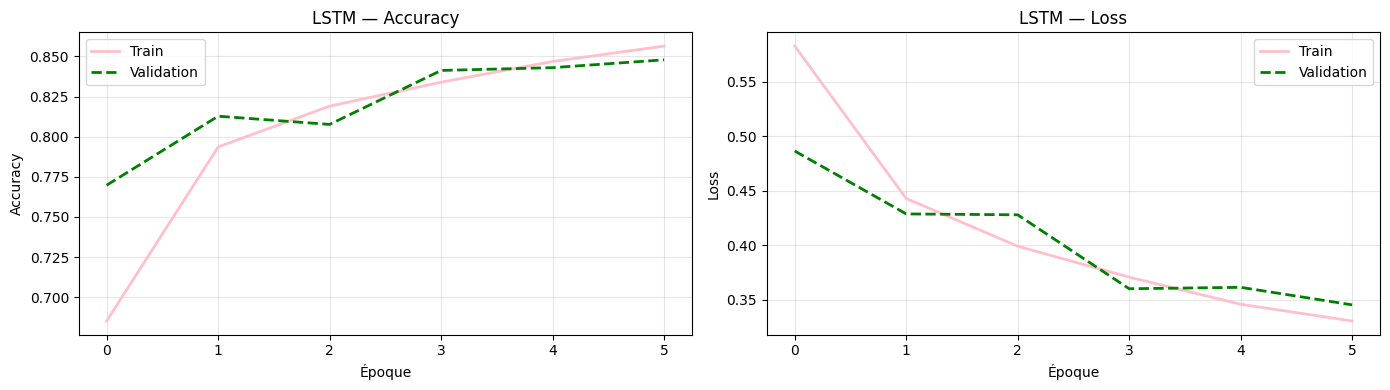

In [24]:
score_lstm = model_lstm.evaluate(X_test, y_test, verbose=1)
print('\n=== LSTM ===')
print('Test Loss     :', round(score_lstm[0], 4))
print('Test Accuracy :', round(score_lstm[1], 4))

plot_history(history_lstm, 'LSTM')

## **Comparaison des 3 modèles**

Modèle  Test Loss  Test Accuracy
 Dense     0.5391         0.7430
   CNN     0.3354         0.8490
  LSTM     0.3455         0.8456


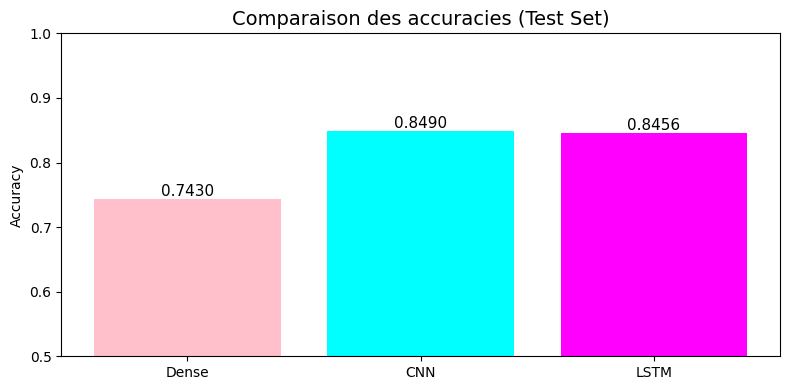

In [25]:
# --- Tableau comparatif ---
results = pd.DataFrame({
    'Modèle': ['Dense', 'CNN', 'LSTM'],
    'Test Loss': [
        round(score_dense[0], 4),
        round(score_cnn[0], 4),
        round(score_lstm[0], 4)
    ],
    'Test Accuracy': [
        round(score_dense[1], 4),
        round(score_cnn[1], 4),
        round(score_lstm[1], 4)
    ]
})

print(results.to_string(index=False))

# Visualisation
plt.figure(figsize=(8, 4))
bars = plt.bar(results['Modèle'], results['Test Accuracy'], color=['pink', 'cyan', 'magenta'])
plt.ylim(0.5, 1.0)
plt.title('Comparaison des accuracies (Test Set)', fontsize=14)
plt.ylabel('Accuracy')
for bar, val in zip(bars, results['Test Accuracy']):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f'{val:.4f}', ha='center', fontsize=11)
plt.tight_layout()
plt.show()


--> Le LSTM capture les dépendances longue portée (ex: négation au début d'une phrase). Le CNN capte les n-grams locaux mais ignore l'ordre global. Le Dense ignore complètement l'ordre des mots.


## **Prédiction sur une instance aléatoire**

In [26]:
# Choisir une instance aléatoire du test set
import random
random.seed(99)
idx = random.randint(0, len(X_test) - 1)

# Prédictions des 3 modèles
instance = X_test[idx].reshape(1, -1)
pred_dense = model_dense.predict(instance, verbose=0)[0][0]
pred_cnn   = model_cnn.predict(instance,   verbose=0)[0][0]
pred_lstm  = model_lstm.predict(instance,  verbose=0)[0][0]

label_true = 'Positif 😊' if y_test[idx] == 1 else 'Négatif 😞'

print(f'Instance n°{idx}')
print(f'Vrai sentiment     : {label_true}')
print(f'Dense  → {pred_dense:.4f} → {"Positif" if pred_dense >= 0.5 else "Négatif"}')
print(f'CNN    → {pred_cnn:.4f}   → {"Positif" if pred_cnn   >= 0.5 else "Négatif"}')
print(f'LSTM   → {pred_lstm:.4f}  → {"Positif" if pred_lstm  >= 0.5 else "Négatif"}')

Instance n°6618
Vrai sentiment     : Négatif 😞
Dense  → 0.0331 → Négatif
CNN    → 0.0137   → Négatif
LSTM   → 0.0006  → Négatif


## **D. Compte rendu**

In [27]:
!pip install gensim fasttext-wheel

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 29.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 64.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 314.2/314.2 kB 19.1 MB/s eta 0:00:00


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer


In [ ]:
MAXLEN        = 100    # longueur max des séquences (en tokens)
NUM_WORDS     = 5000   # taille du vocabulaire conservé
EPOCHS        = 6      # nombre d'époques d'entraînement
BATCH_SIZE    = 128    # taille des mini-batchs
VAL_SPLIT     = 0.2    # fraction de validation pendant l'entraînement
TEST_SIZE     = 0.2    # fraction du dataset réservée au test final
RANDOM_STATE  = 42     # reproductibilité

In [ ]:
import fasttext.util
fasttext.util.download_model('en', if_exists='ignore')
ft = fasttext.load_model('cc.en.300.bin')
print(ft.get_dimension())

In [29]:
import gensim.downloader as api
from gensim.models import KeyedVectors

# Télécharge et charge (nom exact du modèle)
wv = api.load('word2vec-google-news-300')
print(wv)

[==================================================] 100.0% 1662.8/1662.8MB downloaded
KeyedVectors<vector_size=300, 3000000 keys>
